# Hidden Value: Phase 4 - Analysis (Master Notebook)

**This notebook answers the questions. It does not build data.** It reads the drive table that Phase 2 exports and Phase 3 explores, then runs one section per design-doc question.

Grounded in **Design Doc v1.0** and the **Phase 4 Analysis Plan v1.0**.

Two hard rules live in Section 0 and govern everything below:
- **Preview lock:** until every team clears the 40-drive gate (Doc Sec 15), every result here is stamped PREVIEW and is not a finding. It exists so the code is tested and ready.
- **League first, teams second:** the main question is answered across all drives pooled. Team profiles (Section 3) only mean something against that league baseline.

> Run this top to bottom, every time. Do not cherry-pick cells.

## 0. Load, build the analysis frame, and check the gate

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size":13,"axes.titlesize":16,"axes.titleweight":"bold","figure.autolayout":True})

CSV = r"C:\Users\brade\OneDrive - Worcester Polytechnic Institute (wpi.edu)\Desktop\Football\hidden_value_2026_drives.csv"
drives = pd.read_csv(CSV)

# Primary analysis frame (Doc Sec 11 + Sec 14): drop garbage time and clock-expiration drives.
a = drives[(drives["garbage_time"]==0) & (drives["clock_expiration"]==0)].copy()

# Derived per-drive rates (view-only, Phase 4 plan Sec 2)
a["success_rate"]   = a["success_plays"]  / a["qualifying_plays"].replace(0,np.nan)
a["explosive_rate"] = a["explosive_plays"]/ a["qualifying_plays"].replace(0,np.nan)
a["epa_per_play"]   = a["epa_sum"]        / a["qualifying_plays"].replace(0,np.nan)

# ---- THE GATE (Doc Sec 15) ----
gate = drives[drives["garbage_time"]==0].groupby("posteam").size()
PREVIEW = gate.min() < 40
STAMP = "PREVIEW - not a finding" if PREVIEW else "FINDINGS (gate open)"
print("="*60)
print("STATUS:", STAMP)
print(f"drives analyzed: {len(a)} | teams: {a['posteam'].nunique()}")
print(f"fewest drives on one team: {gate.min()}  (need 40 before findings)")
print("="*60)

# ---- helper: standardized regression = 'what matters most' ----
def std_betas(frame, y, xs):
    d = frame[[y]+xs].dropna()
    Z = (d - d.mean())/d.std(ddof=0)
    beta,*_ = np.linalg.lstsq(Z[xs].values, Z[y].values, rcond=None)
    return pd.Series(beta, index=xs).reindex((pd.Series(beta,index=xs)).abs().sort_values(ascending=False).index)

def ols_predict(frame, y, xs):
    d = frame[[y]+xs].dropna().copy()
    X = np.column_stack([np.ones(len(d)), d[xs].values])
    coef,*_ = np.linalg.lstsq(X, d[y].values, rcond=None)
    d["pred"] = X @ coef
    return d

STATUS: PREVIEW - not a finding
drives analyzed: 1070 | teams: 32
fewest drives on one team: 26  (need 40 before findings)


# SECTION 1: THE MAIN QUESTION
**What characteristics of a drive are most strongly associated with scoring?**
Answered across all drives pooled. Each subsection is one design-doc question.

### 1.1  Efficiency vs explosiveness (Q1)

[PREVIEW - not a finding]
correlation of points/drive with EFFICIENCY  (success rate): +0.71
correlation of points/drive with EXPLOSIVENESS(expl. rate) : +0.60
higher magnitude = stronger link to scoring. (team-level, tiny sample in preview)


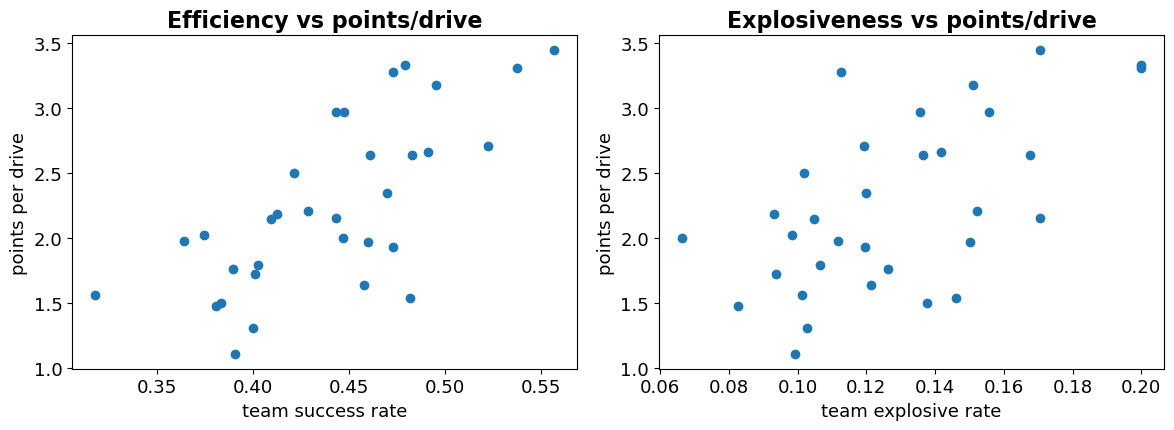

In [2]:
g = a.groupby("posteam")
tm = pd.DataFrame({
    "drives": g.size(),
    "ppd": g["offensive_points"].mean(),
    "success_rate":   g["success_plays"].sum()/g["qualifying_plays"].sum(),
    "explosive_rate": g["explosive_plays"].sum()/g["qualifying_plays"].sum(),
    "avg_start": g["start_yardline_100"].mean(),
    "rz_rate":   g["reached_20"].mean(),
    "to_rate":   g["turnovers"].mean(),
})

c_eff = tm["ppd"].corr(tm["success_rate"])
c_exp = tm["ppd"].corr(tm["explosive_rate"])
print(f"[{STAMP}]")
print(f"correlation of points/drive with EFFICIENCY  (success rate): {c_eff:+.2f}")
print(f"correlation of points/drive with EXPLOSIVENESS(expl. rate) : {c_exp:+.2f}")
print("higher magnitude = stronger link to scoring. (team-level, tiny sample in preview)")

fig,ax = plt.subplots(1,2,figsize=(12,4.5))
ax[0].scatter(tm["success_rate"], tm["ppd"]); ax[0].set_title("Efficiency vs points/drive")
ax[0].set_xlabel("team success rate"); ax[0].set_ylabel("points per drive")
ax[1].scatter(tm["explosive_rate"], tm["ppd"]); ax[1].set_title("Explosiveness vs points/drive")
ax[1].set_xlabel("team explosive rate"); ax[1].set_ylabel("points per drive")
plt.show()

### 1.2  Do explosives compensate for poor efficiency? (Q6)

In [3]:
# 2x2: split drives by efficiency (above/below median success rate) and
# by whether they had ANY explosive play. Compare mean points in each cell.
d = a.dropna(subset=["success_rate"]).copy()
med = d["success_rate"].median()
d["eff"] = np.where(d["success_rate"]>=med, "High efficiency", "Low efficiency")
d["exp"] = np.where(d["explosive_plays"]>0, "Had big play", "No big play")
grid = d.pivot_table(index="eff", columns="exp", values="offensive_points", aggfunc="mean").round(2)
print(f"[{STAMP}]  average points per drive by cell:")
print(grid)
print("\nRead the Low-efficiency / Had-big-play cell: if it scores near the")
print("high-efficiency cells, explosiveness compensates for poor efficiency.")

[PREVIEW - not a finding]  average points per drive by cell:
exp              Had big play  No big play
eff                                       
High efficiency          4.53         2.07
Low efficiency           1.26         0.27

Read the Low-efficiency / Had-big-play cell: if it scores near the
high-efficiency cells, explosiveness compensates for poor efficiency.


### 1.3  Field position (Q2)

[PREVIEW - not a finding]
correlation of points/drive with STARTING FIELD POSITION: -0.22
(avg_start is yards to the end zone; more negative here = worse starts hurt scoring)


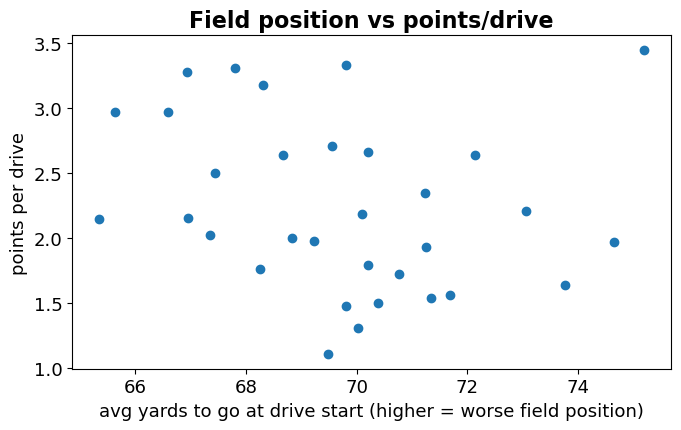

In [4]:
c_fp = tm["ppd"].corr(tm["avg_start"])
print(f"[{STAMP}]")
print(f"correlation of points/drive with STARTING FIELD POSITION: {c_fp:+.2f}")
print("(avg_start is yards to the end zone; more negative here = worse starts hurt scoring)")

plt.figure(figsize=(7,4.5))
plt.scatter(tm["avg_start"], tm["ppd"])
plt.xlabel("avg yards to go at drive start (higher = worse field position)")
plt.ylabel("points per drive"); plt.title("Field position vs points/drive")
plt.show()

### 1.4  Negative plays and turnovers (Q3)

[PREVIEW - not a finding]  points per drive by whether the drive turned it over:
turnovers
no turnover       2.53
turned it over    0.13

correlation of points with # negative plays on the drive: -0.09


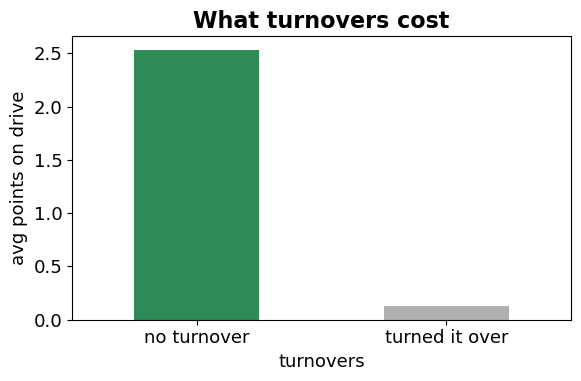

In [5]:
print(f"[{STAMP}]  points per drive by whether the drive turned it over:")
print(a.groupby(a["turnovers"]>0)["offensive_points"].mean().round(2)
        .rename(index={False:"no turnover", True:"turned it over"}).to_string())

c_neg = a["offensive_points"].corr(a["negative_plays"])
print(f"\ncorrelation of points with # negative plays on the drive: {c_neg:+.2f}")

plt.figure(figsize=(6,4))
a.groupby(a["turnovers"]>0)["offensive_points"].mean().plot(
    kind="bar", color=["#2e8b57","#b0b0b0"])
plt.xticks([0,1],["no turnover","turned it over"], rotation=0)
plt.ylabel("avg points on drive"); plt.title("What turnovers cost")
plt.show()

### 1.5  Finishing (Q5)

[PREVIEW - not a finding]  average points per drive by how deep it got:
zone
Didn't reach opp 40    0.02
Got to opp 40          1.66
Reached red zone       5.30


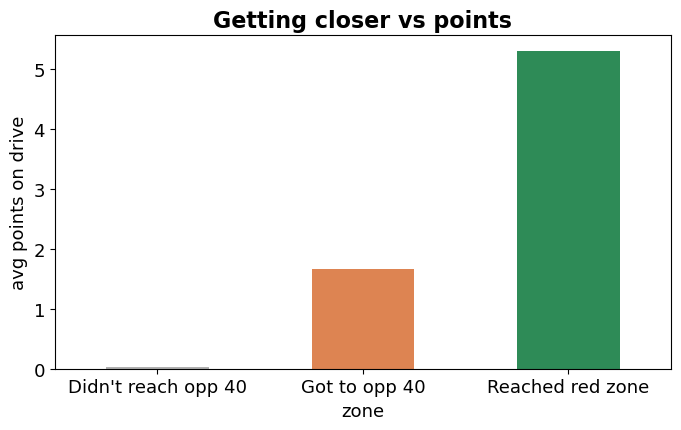

In [6]:
# points by how far the drive got (Doc Sec 7: reached opp 40 / opp 20)
def zone(r):
    if r["reached_20"]==1: return "Reached red zone"
    if r["reached_40"]==1: return "Got to opp 40"
    return "Didn't reach opp 40"
a["zone"] = a.apply(zone, axis=1)
order = ["Didn't reach opp 40","Got to opp 40","Reached red zone"]
fin = a.groupby("zone")["offensive_points"].mean().reindex(order)
print(f"[{STAMP}]  average points per drive by how deep it got:")
print(fin.round(2).to_string())

plt.figure(figsize=(7,4.5))
fin.plot(kind="bar", color=["#b0b0b0","#dd8452","#2e8b57"])
plt.xticks(rotation=0); plt.ylabel("avg points on drive"); plt.title("Getting closer vs points")
plt.show()

### 1.6  What matters most? (master model, Doc Sec 18/20)

In [7]:
# Standardized regression of points on all dimensions. Bigger |beta| = matters more.
xs_full = ["success_rate","explosive_rate","start_yardline_100","reached_20","negative_plays","turnovers"]
xs_epaindep = ["explosive_rate","start_yardline_100","reached_20","negative_plays","turnovers"]  # drops EPA-derived success_rate

print(f"[{STAMP}]  standardized importance (target = observed points/drive)\n")
print("FULL model:")
print(std_betas(a, "offensive_points", xs_full).round(3).to_string())
print("\nEPA-INDEPENDENT model (circularity guard, Doc Sec 20):")
print(std_betas(a, "offensive_points", xs_epaindep).round(3).to_string())
print("\nIf the ranking is stable across both, that ordering is the answer to the main question.")

[PREVIEW - not a finding]  standardized importance (target = observed points/drive)

FULL model:
reached_20            0.585
success_rate          0.268
turnovers            -0.126
start_yardline_100   -0.087
negative_plays       -0.081
explosive_rate        0.056

EPA-INDEPENDENT model (circularity guard, Doc Sec 20):
reached_20            0.702
explosive_rate        0.154
turnovers            -0.139
negative_plays       -0.086
start_yardline_100   -0.077

If the ranking is stable across both, that ordering is the answer to the main question.


# SECTION 2: THIRD DOWN (Q4)
Raw conversion rate works now. The **difficulty adjustment (Plan A5) is blocked**: the drive table has third-down counts but not the distances, so 3rd-and-2 and 3rd-and-11 look identical here. Add third-down distance to Phase 2 before trusting this section.

In [8]:
tm["third_down_rate"] = (a.groupby("posteam")["third_down_conversions"].sum()
                         / a.groupby("posteam")["third_down_attempts"].sum().replace(0,np.nan))
c_3d = tm["ppd"].corr(tm["third_down_rate"])
print(f"[{STAMP}]  RAW third-down rate only (NOT difficulty-adjusted)")
print(f"correlation of points/drive with third-down conversion rate: {c_3d:+.2f}")
print(">> A5 difficulty adjustment pending: needs third-down DISTANCE from the pipeline.")

[PREVIEW - not a finding]  RAW third-down rate only (NOT difficulty-adjusted)
correlation of points/drive with third-down conversion rate: +0.55
>> A5 difficulty adjustment pending: needs third-down DISTANCE from the pipeline.


# SECTION 3: TEAM PROFILES
The Chargers sentence. Before the gate this shows plain 'above/below average' language; after the gate it shows rank out of the league plus a tier. League baseline comes from Section 1.

In [9]:
N = len(tm)
prof = tm.copy()
# ranks (1 = best). turnovers and avg_start are 'lower is better', so rank ascending.
prof["r_eff"]  = prof["success_rate"].rank(ascending=False).astype(int)
prof["r_exp"]  = prof["explosive_rate"].rank(ascending=False).astype(int)
prof["r_fin"]  = prof["rz_rate"].rank(ascending=False).astype(int)
prof["r_fp"]   = prof["avg_start"].rank(ascending=True).astype(int)
prof["r_to"]   = prof["to_rate"].rank(ascending=True).astype(int)
prof["r_ppd"]  = prof["ppd"].rank(ascending=False).astype(int)

def tier(rank, n):
    if rank<=5: return "top 5 (elite)"
    if rank<=10: return "top 10 (strong)"
    if rank>n-5: return "bottom 5 (worst)"
    if rank>n-10: return "bottom 10 (weak)"
    return "middle of the pack"

def team_profile(team):
    if team not in prof.index:
        print("no data for", team); return
    row = prof.loc[team]
    dims = [("Efficiency","r_eff"),("Explosiveness","r_exp"),("Finishing","r_fin"),
            ("Field position","r_fp"),("Turnover avoidance","r_to")]
    print(f"=== {team} profile  [{STAMP}] ===")
    print(f"points per drive: {row['ppd']:.2f}  (rank {int(row['r_ppd'])} of {N})\n")
    for name,rc in dims:
        r = int(row[rc])
        if PREVIEW:
            print(f"{name:20s}: {'above' if r<=N/2 else 'below'} average  (small sample - rank hidden)")
        else:
            print(f"{name:20s}: {r} of {N}  ({tier(r,N)})")

# example - change to any team
team_profile(prof.index[0])

=== ARI profile  [PREVIEW - not a finding] ===
points per drive: 2.00  (rank 19 of 32)

Efficiency          : above average  (small sample - rank hidden)
Explosiveness       : below average  (small sample - rank hidden)
Finishing           : above average  (small sample - rank hidden)
Field position      : above average  (small sample - rank hidden)
Turnover avoidance  : below average  (small sample - rank hidden)


# SECTION 4: OVER / UNDERPERFORMANCE (Q7)
Which teams score more or less than their drive quality predicts. Expected points per drive comes from the full model; the gap is over/underperformance. Call it that, never 'luck' (Doc Sec 19).

[PREVIEW - not a finding]  scoring over/underperformance (actual minus expected points per drive):
         actual  expected   gap
posteam                        
IND        2.50      2.03  0.47
BUF        3.33      2.90  0.43
CLE        2.19      1.83  0.36
DAL        3.28      2.95  0.34
MIN        1.56      1.27  0.29
JAX        2.64      2.37  0.27
CAR        2.97      2.71  0.26
WAS        1.97      1.84  0.13
ATL        1.54      1.40  0.13
NYG        2.15      2.01  0.13
PHI        2.03      1.91  0.12
LV         2.97      2.86  0.12
DET        2.71      2.59  0.12
SF         3.44      3.33  0.11
NO         2.34      2.27  0.07
PIT        1.79      1.73  0.06
BAL        3.31      3.32 -0.00
HOU        2.21      2.22 -0.01
LAC        1.31      1.38 -0.07
DEN        1.73      1.82 -0.09
CIN        2.64      2.73 -0.09
TB         1.48      1.57 -0.09
KC         3.18      3.31 -0.13
ARI        2.00      2.16 -0.16
GB         1.76      1.98 -0.22
NYJ        1.93      2.19 -0.26
SEA  

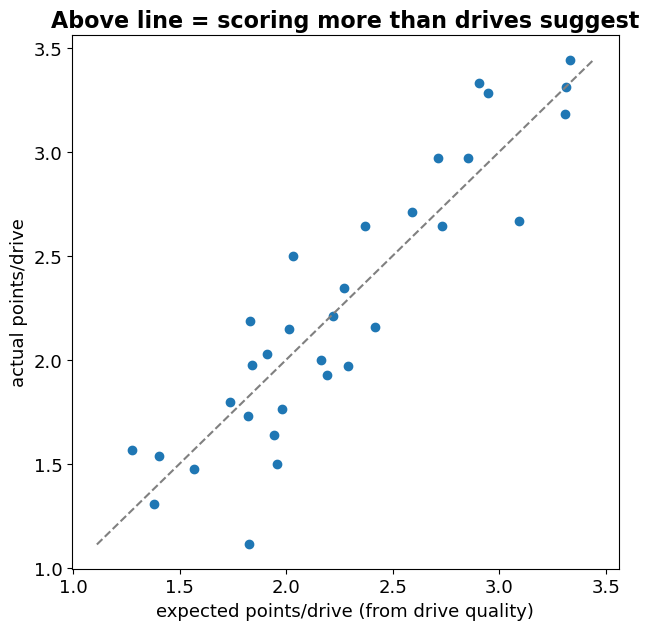

In [10]:
pred = ols_predict(a, "offensive_points",
                   ["success_rate","explosive_rate","start_yardline_100","reached_20","negative_plays","turnovers"])
pred["posteam"] = a.loc[pred.index, "posteam"]
tp = pred.groupby("posteam").agg(actual=("offensive_points","mean"), expected=("pred","mean"))
tp["gap"] = (tp["actual"]-tp["expected"]).round(2)
print(f"[{STAMP}]  scoring over/underperformance (actual minus expected points per drive):")
print(tp.sort_values("gap", ascending=False).round(2).to_string())

plt.figure(figsize=(6.5,6.5))
plt.scatter(tp["expected"], tp["actual"])
lo,hi = tp[["expected","actual"]].min().min(), tp[["expected","actual"]].max().max()
plt.plot([lo,hi],[lo,hi],"--",color="gray")
plt.xlabel("expected points/drive (from drive quality)")
plt.ylabel("actual points/drive"); plt.title("Above line = scoring more than drives suggest")
plt.show()

SCORING HOT (more points than their drives usually produce):
  IND: scoring about 0.5 more points per drive than expected
  BUF: scoring about 0.4 more points per drive than expected

SCORING COLD (leaving points on the field):
  CHI: scoring about 0.4 fewer points per drive than expected
  MIA: scoring about 0.5 fewer points per drive than expected
  TEN: scoring about 0.7 fewer points per drive than expected


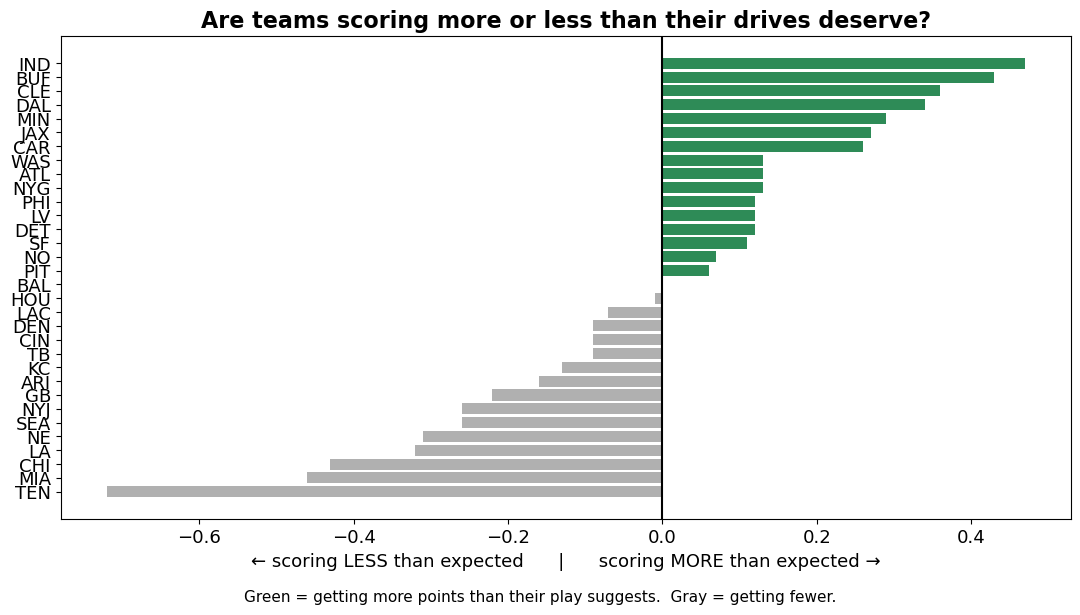

In [11]:
# ---- FAN VERSION: who's scoring more or less than they should ----
import matplotlib.pyplot as plt

tp2 = tp.sort_values("gap", ascending=False).copy()
hot  = tp2[tp2["gap"] > 0.4]
cold = tp2[tp2["gap"] < -0.4]

print("SCORING HOT (more points than their drives usually produce):")
for tm_, r in hot.iterrows():
    print(f"  {tm_}: scoring about {r['gap']:.1f} more points per drive than expected")
print("\nSCORING COLD (leaving points on the field):")
for tm_, r in cold.iterrows():
    print(f"  {tm_}: scoring about {abs(r['gap']):.1f} fewer points per drive than expected")

# simple bar: green = overperforming, gray = underperforming
plt.figure(figsize=(11,6))
colors = ["#2e8b57" if g > 0 else "#b0b0b0" for g in tp2["gap"]]
plt.barh(tp2.index[::-1], tp2["gap"][::-1], color=colors[::-1])
plt.axvline(0, color="black")
plt.title("Are teams scoring more or less than their drives deserve?")
plt.xlabel("← scoring LESS than expected      |      scoring MORE than expected →")
plt.figtext(0.5, -0.02, "Green = getting more points than their play suggests.  Gray = getting fewer.",
            ha="center", fontsize=11)
plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# UNIFIED TEAM DASHBOARD - offense + defense + gaps in one table
# ============================================================
import numpy as np, pandas as pd

xs = ["success_rate","explosive_rate","start_yardline_100","negative_plays","turnovers"]

def expected_pts(frame, group_col):
    d = frame.dropna(subset=xs+["offensive_points"]).copy()
    X = np.column_stack([np.ones(len(d)), d[xs].values])
    coef,*_ = np.linalg.lstsq(X, d["offensive_points"].values, rcond=None)
    d["pred"] = X @ coef
    return d.groupby(group_col).agg(actual=("offensive_points","mean"),
                                    expected=("pred","mean"))

off  = a.groupby("posteam")["offensive_points"].mean().rename("off_ppd")
deff = a.groupby("defteam")["offensive_points"].mean().rename("def_ppd_allowed")
_og = expected_pts(a,"posteam"); off_gap = (_og["actual"]-_og["expected"]).rename("off_gap")
_dg = expected_pts(a,"defteam"); def_gap = (_dg["expected"]-_dg["actual"]).rename("def_gap")

dash = pd.concat([off, deff, off_gap, def_gap], axis=1)
dash["net_quality"] = dash["off_ppd"] - dash["def_ppd_allowed"]   # higher = better overall team
dash = dash.round(2).sort_values("net_quality", ascending=False)

print(f"[{STAMP}]  UNIFIED TEAM DASHBOARD (sorted by net drive quality)")
print("off_ppd: higher=better | def_ppd_allowed: lower=better | net: higher=better")
print("off_gap: + = scored MORE than drives earned | def_gap: + = allowed FEWER than drives suggest")
print(dash.to_string())

[PREVIEW - not a finding]  UNIFIED TEAM DASHBOARD (sorted by net drive quality)
off_ppd: higher=better | def_ppd_allowed: lower=better | net: higher=better
off_gap: + = scored MORE than drives earned | def_gap: + = allowed FEWER than drives suggest
     off_ppd  def_ppd_allowed  off_gap  def_gap  net_quality
SF      3.44             1.62     0.23     0.53         1.82
JAX     2.64             1.27     0.03     0.67         1.37
KC      3.18             2.03     0.07     0.07         1.15
BAL     3.31             2.24    -0.04    -0.11         1.07
BUF     3.33             2.34     0.77    -0.04         0.99
CHI     2.67             1.71    -0.13     0.45         0.96
SEA     2.16             1.32    -0.39     0.01         0.84
LV      2.97             2.32     0.27    -0.07         0.65
CAR     2.97             2.56     0.24    -0.28         0.41
NYG     2.15             1.74     0.10    -0.01         0.41
CIN     2.64             2.30     0.01    -0.27         0.34
MIN     1.56       

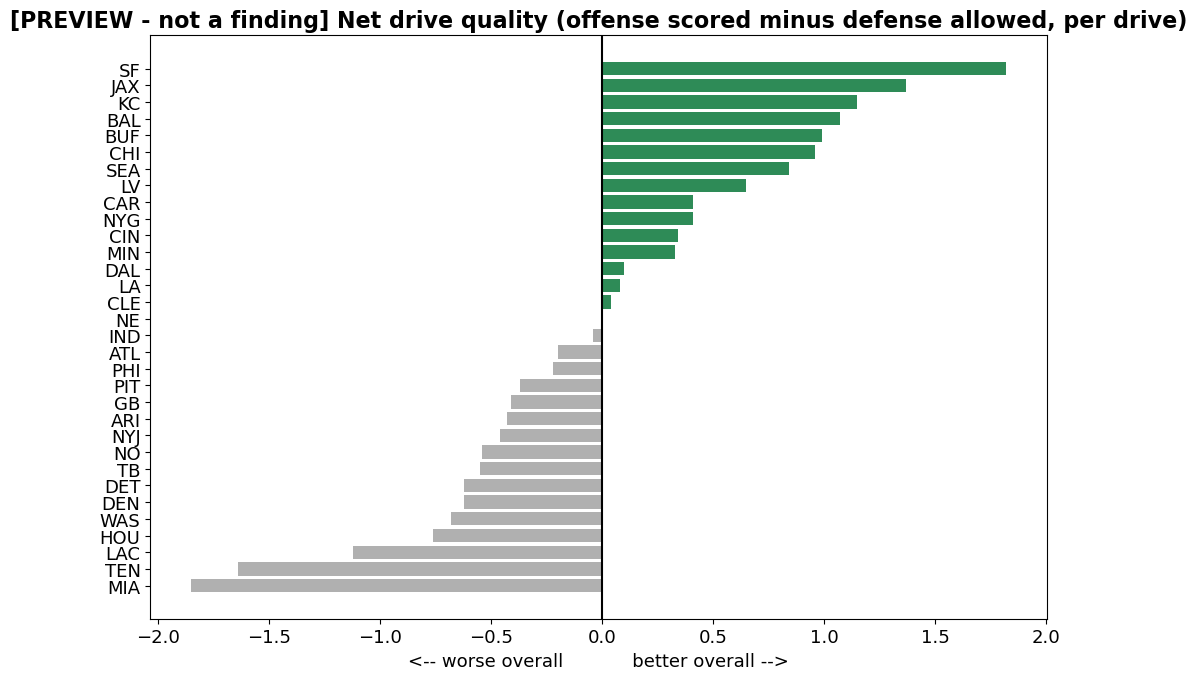

Top = best two-sided teams by underlying play, regardless of record.


In [13]:
# ============================================================
# NET DRIVE QUALITY - offense minus defense allowed, per team
# ============================================================
import matplotlib.pyplot as plt
d = dash.copy()
plt.figure(figsize=(10,7))
colors = ["#2e8b57" if v>0 else "#b0b0b0" for v in d["net_quality"]]
plt.barh(d.index[::-1], d["net_quality"][::-1], color=colors[::-1])
plt.axvline(0, color="black")
plt.title(f"[{STAMP}] Net drive quality (offense scored minus defense allowed, per drive)")
plt.xlabel("<-- worse overall            better overall -->")
plt.tight_layout(); plt.show()
print("Top = best two-sided teams by underlying play, regardless of record.")

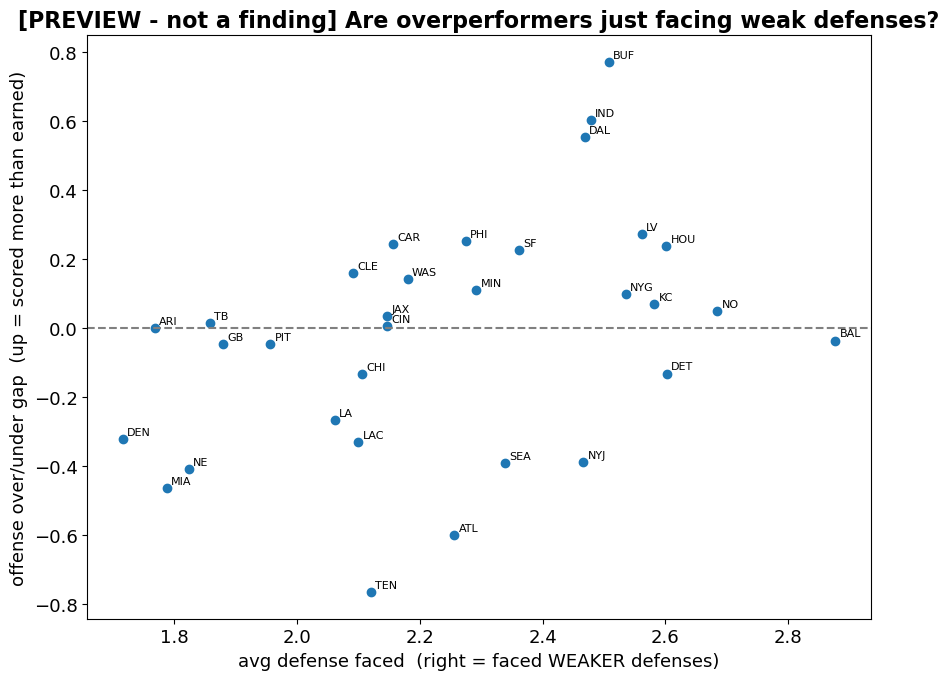

Top-right = overperformed AND faced weak defenses (possible luck).
Top-left  = overperformed despite tough defenses (more likely real).
NOTE: descriptive first pass, NOT a true opponent adjustment (that's Week 5+).


In [14]:
# ============================================================
# ARE OVERPERFORMERS JUST PLAYING WEAK DEFENSES?
# x = avg defense faced (right = weaker D) | y = offense over/under gap
# ============================================================
def_strength = a.groupby("defteam")["offensive_points"].mean()   # ppd each defense allows
a2 = a.copy()
a2["opp_def_ppd_allowed"] = a2["defteam"].map(def_strength)
sos = a2.groupby("posteam")["opp_def_ppd_allowed"].mean().rename("avg_def_faced")

plot_df = pd.concat([sos, off_gap], axis=1).dropna()
plt.figure(figsize=(9,7))
plt.scatter(plot_df["avg_def_faced"], plot_df["off_gap"])
for team,row in plot_df.iterrows():
    plt.annotate(team,(row["avg_def_faced"],row["off_gap"]),fontsize=8,
                 xytext=(3,3),textcoords="offset points")
plt.axhline(0,color="gray",ls="--")
plt.xlabel("avg defense faced  (right = faced WEAKER defenses)")
plt.ylabel("offense over/under gap  (up = scored more than earned)")
plt.title(f"[{STAMP}] Are overperformers just facing weak defenses?")
plt.tight_layout(); plt.show()
print("Top-right = overperformed AND faced weak defenses (possible luck).")
print("Top-left  = overperformed despite tough defenses (more likely real).")
print("NOTE: descriptive first pass, NOT a true opponent adjustment (that's Week 5+).")

## Weekly rhythm

1. Run Phase 2 to rebuild the CSV with the new week's games.
2. Run this notebook top to bottom.
3. Read the banner. If it still says PREVIEW, these are previews, not findings.
4. When the gate opens, the exact same cells become your findings, and the team profiles switch from 'above/below average' to real ranks.

Nothing here is a conclusion until the banner says so.